In [2]:
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
Hospital_df = pd.read_excel('Hospital data analysis.xlsx')
Hospital_df


,Patient_ID,Admission_Date,Department,City,Gender,Age,Visit_Type,Ward_Type,Treatment_Cost,Length_of_Stay_Days,Waiting_Time_Min,Number_of_Tests,Readmission_30_Days
0,2001,2026-01-03,Cardiology,Pune,Male,62,Emergency,General Ward,4200,3,85,2,1
1,2002,2026-01-05,Orthopedics,Pune,Female,45,OPD,General Ward,2800,2,35,1,0
2,2003,2026-01-07,Neurology,Mumbai,Male,58,Emergency,ICU,12500,7,110,4,1
3,2004,2026-01-10,Pediatrics,Pune,Female,8,OPD,General Ward,1800,1,25,0,0
4,2005,2026-01-12,General Medicine,Nashik,Male,51,OPD,General Ward,2200,2,40,1,0
5,2006,2026-01-15,Cardiology,Mumbai,Female,67,Emergency,ICU,14800,8,125,5,1
6,2007,2026-01-18,Orthopedics,Nashik,Male,39,OPD,Semi Private,5200,3,45,2,0
7,2008,2026-01-21,Neurology,Pune,Female,71,Emergency,ICU,13200,6,105,4,1
8,2009,2026-01-24,Pediatrics,Mumbai,Male,12,OPD,General Ward,2100,1,30,0,0
9,2010,2026-01-27,General Medicine,Pune,Female,55,OPD,Semi Private,3600,2,38,1,0


In [ ]:
Hospital_df["Admission_Date"] = pd.to_datetime(Hospital_df["Admission_Date"])
Hospital_df

In [ ]:
Hospital_df["Month"] = Hospital_df["Admission_Date"].dt.month_name()
monthly_patients = Hospital_df.groupby("Month")["Patient_ID"].count()
print(monthly_patients)

Month
February    10
January     10
March       10
Name: Patient_ID, dtype: int64


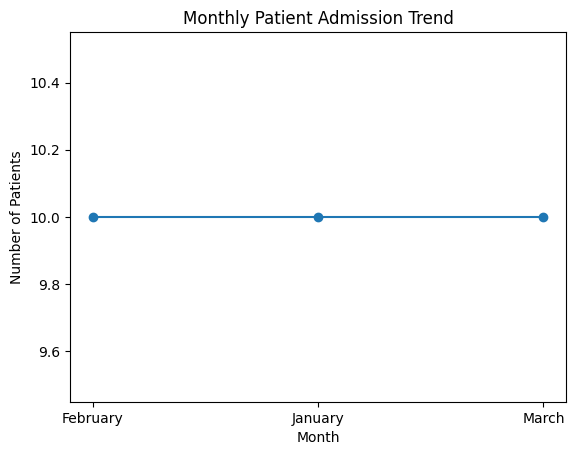

In [15]:
plt.plot(monthly_patients.index, monthly_patients.values, marker="o")
plt.xlabel("Month")
plt.ylabel("Number of Patients")
plt.title("Monthly Patient Admission Trend")
plt.show()

In [20]:
summary = Hospital_df.groupby("Department")["Treatment_Cost"].agg(
    ["sum", "mean", "min", "max", "count"]
)

print(summary)

                    sum          mean   min    max  count
Department                                               
Cardiology        73800  12300.000000  4200  16500      6
General Medicine  20900   3483.333333  2200   4700      6
Neurology         76000  12666.666667  9800  15800      6
Orthopedics       24600   4100.000000  2600   6100      6
Pediatrics        11850   1975.000000  1750   2300      6


In [21]:
department_patients = Hospital_df.groupby("Department")["Patient_ID"].count()
print(department_patients)

Department
Cardiology          6
General Medicine    6
Neurology           6
Orthopedics         6
Pediatrics          6
Name: Patient_ID, dtype: int64


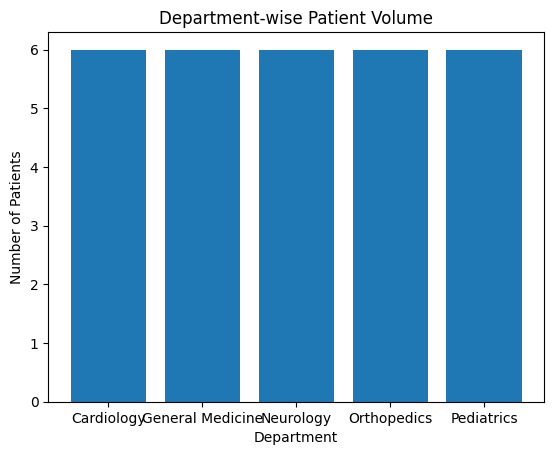

In [23]:
plt.bar(department_patients.index,department_patients.values)
plt.xlabel("Department")
plt.ylabel("Number of Patients")
plt.title("Department-wise Patient Volume")
plt.show()

In [24]:
print("Highest workload department:",department_patients.idxmax())

print("Lowest workload department:",department_patients.idxmin())

Highest workload department: Cardiology
Lowest workload department: Cardiology


In [25]:
department_cost = (Hospital_df.groupby("Department")["Treatment_Cost"].sum().sort_values(ascending=False))
print(department_cost)


Department
Neurology           76000
Cardiology          73800
Orthopedics         24600
General Medicine    20900
Pediatrics          11850
Name: Treatment_Cost, dtype: int64


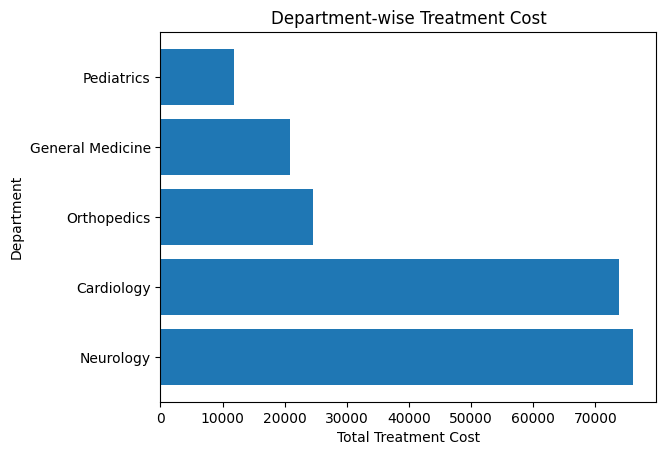

In [26]:
plt.barh(department_cost.index,department_cost.values)
plt.xlabel("Total Treatment Cost")
plt.ylabel("Department")
plt.title("Department-wise Treatment Cost")
plt.show()

In [29]:
print("Highest treatment cost department:",
      department_cost.idxmax())

Highest treatment cost department: Neurology


In [37]:
department_analysis = Hospital_df.groupby("Department").agg(Patient_Volume=("Patient_ID", "count"),Total_Treatment_Cost=("Treatment_Cost", "sum"))
print(department_analysis)

                  Patient_Volume  Total_Treatment_Cost
Department                                            
Cardiology                     6                 73800
General Medicine               6                 20900
Neurology                      6                 76000
Orthopedics                    6                 24600
Pediatrics                     6                 11850


In [ ]:
highest_cost_department = department_analysis["Total_Treatment_Cost"].idxmax()
highest_cost = department_analysis["Total_Treatment_Cost"].max()
print("Department with highest treatment cost:", highest_cost_department)
print("Highest treatment cost:", highest_cost)

Department with highest treatment cost: Neurology
Highest treatment cost: 76000


In [39]:
highest_volume_department = department_analysis["Patient_Volume"].idxmax()
print("Highest volume department:", highest_volume_department)

Highest volume department: Cardiology


In [40]:
highest_cost_department = department_analysis["Total_Treatment_Cost"].idxmax()
if highest_volume_department == highest_cost_department:
    print("Yes, the highest-volume department is also the highest-cost department.")
else:
    print("No, the highest-volume and highest-cost departments are different.")

No, the highest-volume and highest-cost departments are different.


In [46]:
patient_type = Hospital_df["Visit_Type"].value_counts()
print(patient_type)

Visit_Type
OPD          16
Emergency    14
Name: count, dtype: int64


Text(0.5, 1.0, 'OPD vs Emergency Patients')

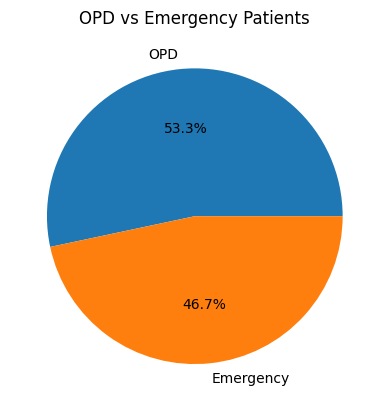

In [47]:
plt.pie(patient_type.values,labels=patient_type.index,autopct="%1.1f%%")
plt.title("OPD vs Emergency Patients")

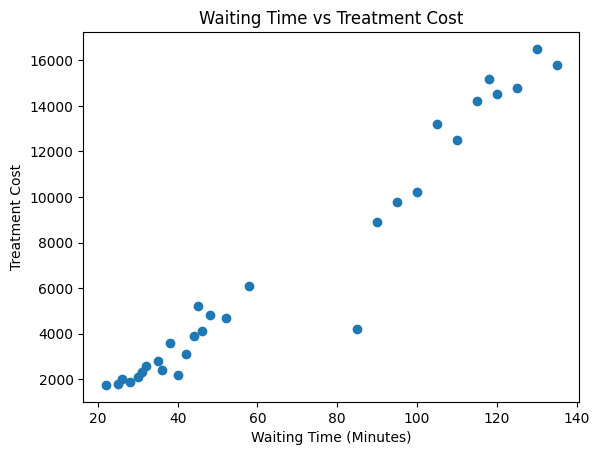

In [48]:
plt.scatter(Hospital_df["Waiting_Time_Min"],Hospital_df["Treatment_Cost"])

plt.xlabel("Waiting Time (Minutes)")
plt.ylabel("Treatment Cost")
plt.title("Waiting Time vs Treatment Cost")

plt.show()

In [50]:
correlation = Hospital_df["Waiting_Time_Min"].corr(Hospital_df["Treatment_Cost"])
print("Correlation between Waiting Time and Treatment Cost:", round(correlation, 2))

Correlation between Waiting Time and Treatment Cost: 0.97


In [51]:
Hospital_dfcorrelation = Hospital_df["Waiting_Time_Min"].corr(Hospital_df["Treatment_Cost"])
print("Correlation between Waiting Time and Treatment Cost:", round(correlation, 2))
if correlation > 0.5:
    print("Yes, expensive cases generally have longer waiting times.")
elif correlation < -0.5:
    print("No, expensive cases generally have shorter waiting times.")
else:
    print("There is no strong relationship between waiting time and treatment cost.")

Correlation between Waiting Time and Treatment Cost: 0.97
Yes, expensive cases generally have longer waiting times.


In [60]:
average_waiting = Hospital_df["Waiting_Time_Min"].mean()
std_waiting = Hospital_df["Waiting_Time_Min"].std()
high_waiting = Hospital_df[Hospital_df["Waiting_Time_Min"] > average_waiting + 2 * std_waiting]
print("\nPatients with unusually high waiting times:")
print(high_waiting[["Patient_ID", "Waiting_Time_Min", "Treatment_Cost"]])


Patients with unusually high waiting times:
Empty DataFrame
Columns: [Patient_ID, Waiting_Time_Min, Treatment_Cost]
Index: []


In [64]:
monthly_waiting = (Hospital_df.groupby("Month")["Waiting_Time_Min"].mean())
print(monthly_waiting)

Month
February    66.8
January     63.8
March       70.0
Name: Waiting_Time_Min, dtype: float64


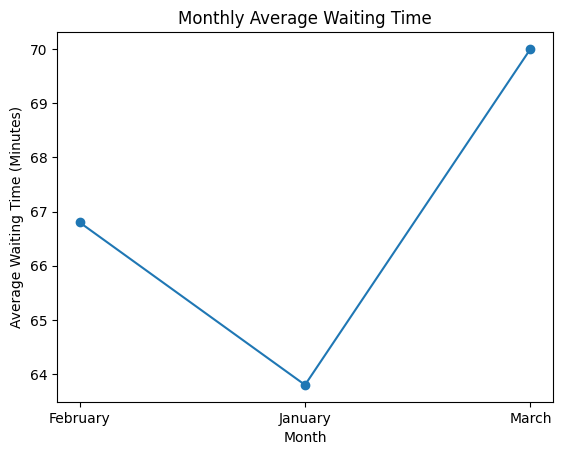

In [62]:
plt.plot(monthly_waiting.index,monthly_waiting.values,marker="o"
)
plt.xlabel("Month")
plt.ylabel("Average Waiting Time (Minutes)")
plt.title("Monthly Average Waiting Time")

plt.show()

In [72]:
print("highest waiting time : ",monthly_waiting.idxmax())
print("lowest waiting time : ",monthly_waiting.idxmin())

highest waiting time :  March
lowest waiting time :  January


In [73]:
first_month_waiting = monthly_waiting.iloc[0]
last_month_waiting = monthly_waiting.iloc[-1]

print("First Month Average Waiting Time:",round(first_month_waiting, 2))
print("Last Month Average Waiting Time:",round(last_month_waiting, 2))

if last_month_waiting < first_month_waiting:
    print("Operational efficiency is improving.")
elif last_month_waiting > first_month_waiting:
    print("Operational efficiency is worsening.")
else:
    print("Operational efficiency is stable.")


First Month Average Waiting Time: 66.8
Last Month Average Waiting Time: 70.0
Operational efficiency is worsening.


In [ ]:
department_stay = (Hospital_df.groupby("Department")["Length_of_Stay_Days"].mean())
print(department_stay)

Department
Cardiology          6.666667
General Medicine    2.500000
Neurology           6.666667
Orthopedics         2.666667
Pediatrics          1.000000
Name: Length_of_Stay_Days, dtype: float64


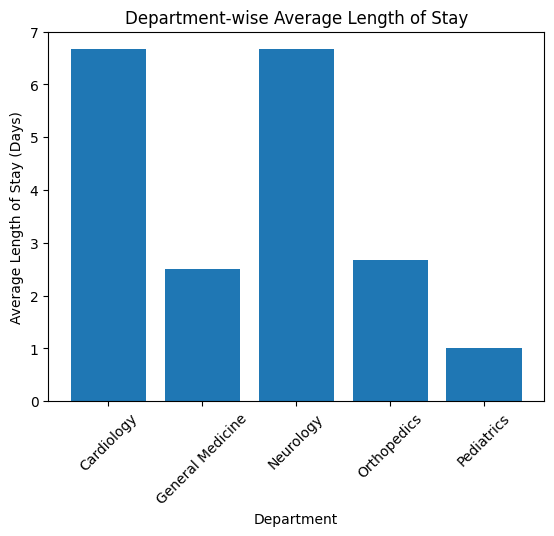

In [82]:
plt.bar(department_stay.index,department_stay.values)

plt.xlabel("Department")
plt.ylabel("Average Length of Stay (Days)")
plt.title("Department-wise Average Length of Stay")
plt.xticks(rotation=45)

plt.show()

In [78]:
longest_department = department_stay.idxmax()
longest_stay = department_stay.max()

print("Department with longest average stay:")
print(longest_department)

print("Average stay:",round(longest_stay, 2), "days")

Department with longest average stay:
Cardiology
Average stay: 6.67 days


In [79]:
shortest_department = department_stay.idxmin()
shortest_stay = department_stay.min()

print("Department with shortest average stay:")
print(shortest_department)

print("Average stay:",round(shortest_stay, 2), "days")

Department with shortest average stay:
Pediatrics
Average stay: 1.0 days


In [80]:
overall_average = Hospital_df["Length_of_Stay_Days"].mean()
bed_capacity_departments = department_stay[department_stay > overall_average]

print("\nDepartments with higher-than-average stay:")
print(bed_capacity_departments)


Departments with higher-than-average stay:
Department
Cardiology    6.666667
Neurology     6.666667
Name: Length_of_Stay_Days, dtype: float64


In [83]:
print("Longest average stay department:",department_stay.idxmax())

Longest average stay department: Cardiology


In [84]:
city_patients = (Hospital_df.groupby("City")["Patient_ID"].count().sort_values(ascending=False))
print(city_patients)

City
Pune      12
Mumbai    10
Nashik     8
Name: Patient_ID, dtype: int64


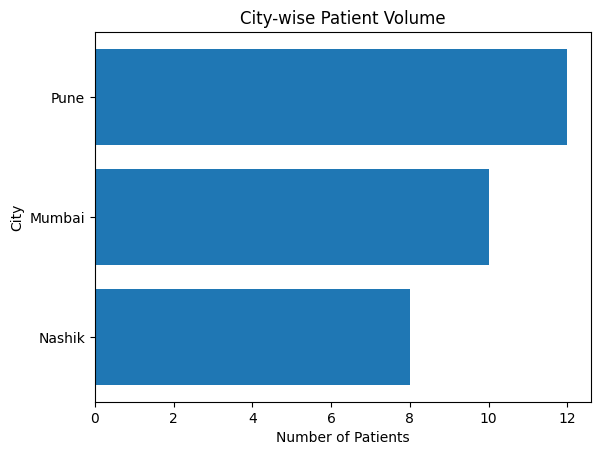

In [85]:
plt.barh(city_patients.index,city_patients.values)

plt.xlabel("Number of Patients")
plt.ylabel("City")
plt.title("City-wise Patient Volume")

plt.gca().invert_yaxis()

plt.show()

In [86]:
print("Highest demand city:",city_patients.idxmax())
print("Lowest demand city:",city_patients.idxmin())

Highest demand city: Pune
Lowest demand city: Nashik


In [87]:
city_percentage = (city_patients / city_patients.sum()) * 100
print("Patient demand percentage:")
print(city_percentage.round(2))

Patient demand percentage:
City
Pune      40.00
Mumbai    33.33
Nashik    26.67
Name: Patient_ID, dtype: float64


In [6]:
readmission_count = Hospital_df["Readmission_30_Days"].value_counts()

not_readmitted = readmission_count.get(0, 0)
readmitted = readmission_count.get(1, 0)

print("Not Readmitted Patients:", not_readmitted)
print("Readmitted Patients:", readmitted)

Not Readmitted Patients: 19
Readmitted Patients: 11


In [7]:
total_patients = not_readmitted + readmitted

not_readmitted_percentage = (
    not_readmitted / total_patients
) * 100

readmitted_percentage = (
    readmitted / total_patients
) * 100

print("\nNot Readmitted Percentage:",
      round(not_readmitted_percentage, 2), "%")

print("Readmitted Percentage:",
      round(readmitted_percentage, 2), "%")


Not Readmitted Percentage: 63.33 %
Readmitted Percentage: 36.67 %


In [8]:
readmission_rate = readmitted_percentage

print("\nReadmission Rate:",
      round(readmission_rate, 2), "%")

if readmission_rate >= 20:
    print("Readmission level is high and requires attention.")

elif readmission_rate >= 10:
    print("Readmission level is moderate and should be monitored.")

else:
    print("Readmission level is relatively low.")


Readmission Rate: 36.67 %
Readmission level is high and requires attention.


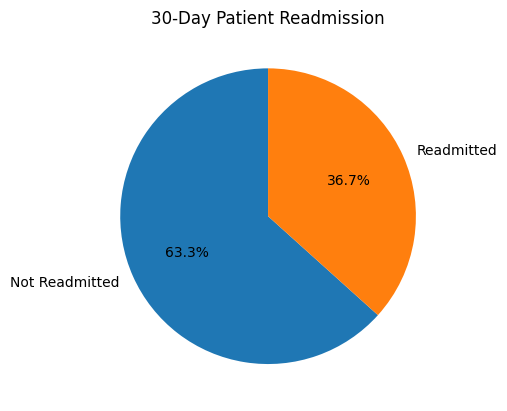

In [ ]:

labels = ["Not Readmitted","Readmitted"]
values = [not_readmitted,readmitted]
plt.pie(values,labels=labels,autopct="%1.1f%%",startangle=90)

plt.title("30-Day Patient Readmission")
plt.show()

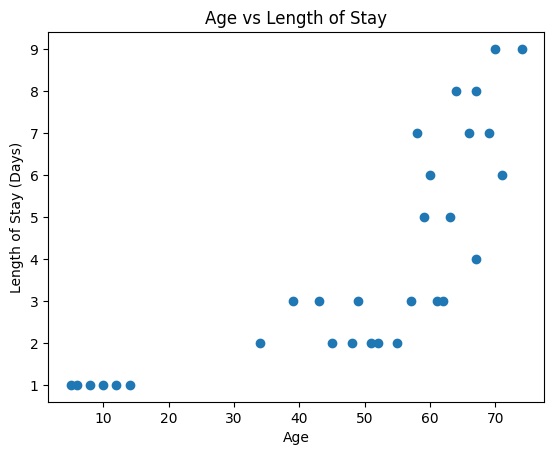

In [11]:
plt.scatter(Hospital_df["Age"],Hospital_df["Length_of_Stay_Days"])

plt.xlabel("Age")
plt.ylabel("Length of Stay (Days)")
plt.title("Age vs Length of Stay")

plt.show()

In [13]:
correlation = Hospital_df["Age"].corr(Hospital_df["Length_of_Stay_Days"])

print("Correlation between Age and Length of Stay:",round(correlation, 2))

Correlation between Age and Length of Stay: 0.78


In [14]:
if correlation > 0.5:
    print("Older patients generally tend to stay longer.")
elif correlation < -0.5:
    print("Older patients generally tend to have shorter stays.")
else:
    print("There is no strong relationship between age and length of stay.")


Older patients generally tend to stay longer.


In [ ]:
average_stay = Hospital_df["Length_of_Stay_Days"].mean()
std_stay = Hospital_df["Length_of_Stay_Days"].std()
unusual_cases = Hospital_df[Hospital_df["Length_of_Stay_Days"] >average_stay + 2 * std_stay]

print("\nUnusual cases with very long hospital stays:")

print(unusual_cases[["Patient_ID", "Age", "Length_of_Stay_Days"]])


Unusual cases with very long hospital stays:
Empty DataFrame
Columns: [Patient_ID, Age, Length_of_Stay_Days]
Index: []
